# Module 02: Math for Deep Learning

Deep learning is built from numerical operations. A neural network takes tensors, multiplies them by weight matrices, adds biases, applies functions, calculates loss, and uses gradients to improve the weights.

This module teaches only the math needed to understand that process. It avoids unnecessary abstract math and keeps every concept connected to deep learning.


## Module Goal

By the end of this module, you should understand:

- how data is represented as tensors
- how tensor shapes control whether operations work
- how a neural-network layer uses matrix multiplication
- why broadcasting is used for bias addition
- how norms and similarity are used in embeddings and regularization
- why derivatives and gradients are needed for learning
- how the chain rule makes backpropagation possible
- how probability connects to classification outputs
- why entropy, cross-entropy, and KL divergence appear in loss functions
- why numerical stability matters in softmax and log calculations

This module is the bridge between Module 1 foundations and later modules on backpropagation, optimizers, transformers, VAEs, and deployment.


## Module Outline

1. Why math matters in deep learning
2. Scalars, vectors, matrices, and tensors
3. Shape, axis, rank, and dtype
4. Reshape, flatten, transpose, and batch dimension
5. Elementwise operations
6. Dot product: the math inside one neuron
7. Matrix multiplication: the math inside one layer
8. Broadcasting: adding bias to a batch
9. Norms: L1, L2, and Frobenius
10. Distance and cosine similarity
11. Functions, slope, and derivatives
12. Partial derivatives
13. Gradient vector
14. Gradient descent direction
15. Chain rule
16. Jacobian intuition
17. Hessian and curvature intuition
18. Probability basics
19. Likelihood and log-likelihood
20. Entropy
21. Cross-entropy
22. KL divergence
23. Numerical stability
24. Stable softmax and log-sum-exp
25. Common math mistakes in deep learning
26. Final checklist


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10

rng = np.random.default_rng(42)


## Step 1: Why Math Matters in Deep Learning

Deep learning training is not magic. It is repeated numerical calculation.

A simple neural network layer does this:

$$
Z = XW + b
$$

Then applies an activation:

$$
A = f(Z)
$$

Then a loss function measures error:

$$
\text{loss} = L(\hat{y}, y)
$$

Then gradients tell the optimizer how to change weights:

$$
W_{new} = W_{old} - \eta \frac{\partial L}{\partial W}
$$

Where:

- $X$ = input data
- $W$ = weights
- $b$ = bias
- $f$ = activation function
- $L$ = loss function
- $\eta$ = learning rate
- $\frac{\partial L}{\partial W}$ = gradient of loss with respect to weights

So the math foundation is needed because every deep learning model is built from these operations.


## Step 2: Scalars, Vectors, Matrices, and Tensors

### What is a scalar?

A **scalar** is one number.

Example:

```text
learning_rate = 0.001
```

### What is a vector?

A **vector** is a 1D list of numbers.

Example: one employee represented by three features:

```text
[years_experience, salary_scaled, training_hours]
```

### What is a matrix?

A **matrix** is a 2D table of numbers.

Example: many employees, each with multiple features:

```text
rows = employees
columns = features
```

### What is a tensor?

A **tensor** is a general multi-dimensional array. Scalars, vectors, and matrices are all tensors too.

| Object | Example shape | Deep learning meaning |
|---|---:|---|
| Scalar | `()` | one value, like loss or learning rate |
| Vector | `(features,)` | one sample, one embedding |
| Matrix | `(samples, features)` | tabular batch or flattened images |
| 3D tensor | `(samples, time, features)` | sequence batch |
| 4D tensor | `(batch, height, width, channels)` | image batch |


In [2]:
scalar = np.array(3.14)
vector = np.array([1.0, 2.0, 3.0])
matrix = np.array([[1, 2, 3], [4, 5, 6]])
tensor_3d = np.zeros((2, 4, 3))
tensor_4d = np.zeros((8, 28, 28, 1))

objects = [
    ('scalar', scalar, 'one number'),
    ('vector', vector, 'one sample or embedding'),
    ('matrix', matrix, 'batch of rows and features'),
    ('3D tensor', tensor_3d, 'batch of sequences'),
    ('4D tensor', tensor_4d, 'batch of grayscale images'),
]

display(pd.DataFrame({
    'Object': [x[0] for x in objects],
    'Shape': [x[1].shape for x in objects],
    'Rank / ndim': [x[1].ndim for x in objects],
    'Meaning': [x[2] for x in objects]
}))


,Object,Shape,Rank / ndim,Meaning
0,scalar,(),0,one number
1,vector,"(3,)",1,one sample or embedding
2,matrix,"(2, 3)",2,batch of rows and features
3,3D tensor,"(2, 4, 3)",3,batch of sequences
4,4D tensor,"(8, 28, 28, 1)",4,batch of grayscale images


### Output Meaning

The **rank** or `ndim` tells how many axes the tensor has.

A common beginner error is to say “tensor” only for 3D or 4D data. In deep learning, even one number can be treated as a tensor.


## Step 3: Shape, Axis, Rank, and dtype

### Shape

The **shape** tells the size of each dimension.

Example:

```text
(32, 10)
```

means 32 rows and 10 features.

### Axis

An **axis** is one dimension of a tensor.

For shape `(32, 10)`:

- axis 0 = rows / samples
- axis 1 = features

### Rank

The **rank** is the number of dimensions.

Example:

```text
shape (32, 10) → rank 2
```

### dtype

The **dtype** tells the type of number stored, such as `float32`, `float64`, or `int64`.

Deep learning models usually train with floating-point numbers, often `float32` or lower precision.


In [3]:
X = rng.normal(size=(5, 3)).astype(np.float32)
shape_info = pd.DataFrame({
    'Property': ['shape', 'axis 0 size', 'axis 1 size', 'rank / ndim', 'dtype'],
    'Value': [X.shape, X.shape[0], X.shape[1], X.ndim, X.dtype]
})
display(shape_info)
display(pd.DataFrame(X, columns=['feature_1', 'feature_2', 'feature_3']).round(3))


,Property,Value
0,shape,"(5, 3)"
1,axis 0 size,5
2,axis 1 size,3
3,rank / ndim,2
4,dtype,float32


,feature_1,feature_2,feature_3
0,0.305,-1.040,0.750
1,0.941,-1.951,-1.302
2,0.128,-0.316,-0.017
3,-0.853,0.879,0.778
4,0.066,1.127,0.468


### Common Shape Mistake

A model may expect this:

```text
(batch, features)
```

But the user may pass this:

```text
(features,)
```

These are not the same.

Example:

```text
(3,)      → one vector without batch axis
(1, 3)   → one sample with batch axis
```


In [4]:
one_sample_no_batch = np.array([1.0, 2.0, 3.0])
one_sample_with_batch = one_sample_no_batch.reshape(1, 3)

print('Without batch axis:', one_sample_no_batch.shape)
print('With batch axis:', one_sample_with_batch.shape)


Without batch axis: (3,)
With batch axis: (1, 3)


## Step 4: Reshape, Flatten, Transpose, and Batch Dimension

### Reshape

`reshape` changes the shape without changing the data values.

### Flatten

`flatten` converts a matrix or tensor into one long vector.

Images are often flattened for simple dense networks:

```text
8 × 8 image → 64 pixel vector
```

### Transpose

`transpose` swaps axes.

Example:

```text
(rows, columns) → (columns, rows)
```

### Batch dimension

The batch dimension groups multiple examples together.

```text
one image:       (8, 8)
batch of images: (10, 8, 8)
```


image shape: (8, 8)
flattened shape: (64,)
transposed shape: (8, 8)
batch shape: (3, 8, 8)


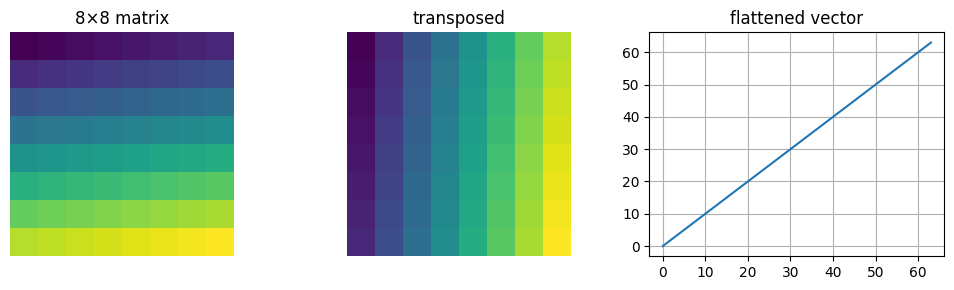

In [5]:
image = np.arange(64).reshape(8, 8)
flat = image.flatten()
transposed = image.T
batch = np.stack([image, image + 100, image + 200])

print('image shape:', image.shape)
print('flattened shape:', flat.shape)
print('transposed shape:', transposed.shape)
print('batch shape:', batch.shape)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(image, cmap='viridis')
axes[0].set_title('8×8 matrix')
axes[1].imshow(transposed, cmap='viridis')
axes[1].set_title('transposed')
axes[2].plot(flat)
axes[2].set_title('flattened vector')
for ax in axes[:2]:
    ax.axis('off')
plt.tight_layout()
plt.show()


## Step 5: Elementwise Operations

An **elementwise operation** applies the same operation to each matching element.

Example:

```text
[1, 2, 3] + [10, 20, 30] = [11, 22, 33]
```

Deep learning uses elementwise operations for:

- activations like ReLU
- adding tensors of the same shape
- multiplying masks
- applying dropout masks
- normalizing values


In [6]:
x = np.array([-2, -1, 0, 1, 2])
relu = np.maximum(0, x)
squared = x ** 2

display(pd.DataFrame({'x': x, 'ReLU(x)': relu, 'x_squared': squared}))


,x,ReLU(x),x_squared
0,-2,0,4
1,-1,0,1
2,0,0,0
3,1,1,1
4,2,2,4


## Step 6: Dot Product — The Math Inside One Neuron

The dot product multiplies matching elements and adds them.

Formula:

$$
x \cdot w = x_1w_1 + x_2w_2 + \dots + x_nw_n
$$

A neuron uses dot product plus bias:

$$
z = x \cdot w + b
$$

So the dot product is the core calculation inside one neuron.


In [7]:
x = np.array([4.0, 2.0, 7.0])
w = np.array([0.8, 1.2, 0.3])
b = -5.0
weighted_sum = np.dot(x, w) + b

calc = pd.DataFrame({
    'feature_x': x,
    'weight_w': w,
    'x_times_w': x * w
})
display(calc)
print('dot(x, w):', np.dot(x, w))
print('bias:', b)
print('z = dot(x,w)+b:', weighted_sum)


,feature_x,weight_w,x_times_w
0,4.0,0.8,3.2
1,2.0,1.2,2.4
2,7.0,0.3,2.1


dot(x, w): 7.699999999999999
bias: -5.0
z = dot(x,w)+b: 2.6999999999999993


### Output Meaning

Each input feature contributes based on its weight. A larger weight means that feature has more influence on the neuron's weighted sum.

Common mistake: confusing dot product with elementwise multiplication. Dot product returns one number; elementwise multiplication returns a vector.


## Step 7: Matrix Multiplication — The Math Inside One Layer

One neuron uses a dot product.

A layer has many neurons, so it uses matrix multiplication.

Formula:

$$
Z = XW + b
$$

Shape meaning:

```text
X: (batch_size, input_features)
W: (input_features, output_neurons)
b: (output_neurons,)
Z: (batch_size, output_neurons)
```

The middle dimensions must match:

```text
(batch, input_features) @ (input_features, output_neurons)
```


In [8]:
X = np.array([
    [1.0, 2.0, 3.0],
    [4.0, 5.0, 6.0],
    [7.0, 8.0, 9.0]
])
W = rng.normal(0, 0.5, size=(3, 4))
b = rng.normal(0, 0.1, size=(4,))
Z = X @ W + b

shape_table = pd.DataFrame({
    'Tensor': ['X', 'W', 'b', 'Z = XW + b'],
    'Shape': [X.shape, W.shape, b.shape, Z.shape],
    'Meaning': ['3 samples, 3 features', '3 input features, 4 neurons', '4 bias values', '3 samples, 4 layer outputs']
})
display(shape_table)
display(pd.DataFrame(Z, columns=[f'neuron_{i}' for i in range(4)]).round(3))


,Tensor,Shape,Meaning
0,X,"(3, 3)","3 samples, 3 features"
1,W,"(3, 4)","3 input features, 4 neurons"
2,b,"(4,)",4 bias values
3,Z = XW + b,"(3, 4)","3 samples, 4 layer outputs"


,neuron_0,neuron_1,neuron_2,neuron_3
0,-0.675,-0.602,-1.645,2.674
1,-2.270,-0.968,-4.633,6.624
2,-3.866,-1.335,-7.621,10.574


### Matrix Multiplication Shape Rule

If:

```text
A shape = (m, n)
B shape = (n, p)
```

Then:

```text
A @ B shape = (m, p)
```

The inner dimensions must match.


## Step 8: Broadcasting — Adding Bias to a Batch

Broadcasting lets NumPy or a deep learning framework automatically expand a smaller tensor to match a larger tensor.

In a layer:

```text
Z = XW + b
```

`XW` may have shape:

```text
(batch_size, output_neurons)
```

`b` may have shape:

```text
(output_neurons,)
```

The bias is automatically added to every row in the batch.


In [9]:
XW = np.array([
    [1.0, 2.0, 3.0],
    [4.0, 5.0, 6.0]
])
b = np.array([10.0, 20.0, 30.0])
Z = XW + b

display(pd.DataFrame(XW, columns=['n1', 'n2', 'n3']))
print('bias shape:', b.shape)
display(pd.DataFrame(Z, columns=['n1_plus_bias', 'n2_plus_bias', 'n3_plus_bias']))


,n1,n2,n3
0,1.0,2.0,3.0
1,4.0,5.0,6.0


bias shape: (3,)


,n1_plus_bias,n2_plus_bias,n3_plus_bias
0,11.0,22.0,33.0
1,14.0,25.0,36.0


### Broadcasting Mistake

Broadcasting is convenient but can hide bugs.

Example: adding a vector with the wrong axis may still run but produce wrong results.

Always check shapes before trusting the output.


## Step 9: Norms — L1, L2, and Frobenius

A norm measures the size or length of a vector or matrix.

### L1 norm

$$
\|x\|_1 = \sum_i |x_i|
$$

### L2 norm

$$
\|x\|_2 = \sqrt{\sum_i x_i^2}
$$

### Frobenius norm for matrices

$$
\|A\|_F = \sqrt{\sum_{i,j} A_{ij}^2}
$$

Where used in deep learning:

- regularization
- weight decay
- measuring embedding size
- distance calculations
- gradient clipping


### Why Norms Exist

A norm answers a simple question:

```text
How large is this vector or matrix?
```

In deep learning, this matters because weights, gradients, embeddings, and errors are all stored as vectors or matrices. If these values become too large, training can become unstable. If they are too small, learning can become slow or vanish.

A norm converts many numbers into one size value.

Example:

```text
vector = [3, 4]
size   = 5 using L2 norm
```

So a norm is not a model by itself. It is a measurement tool used inside training, regularization, similarity, and debugging.


### L1 Norm: Sum of Absolute Values

Formula:

$$
\|x\|_1 = |x_1| + |x_2| + \dots + |x_n|
$$

Example:

```text
x = [3, -4, 2]
L1 = |3| + |-4| + |2| = 9
```

**Where it is used:** L1 regularization, sparse models, feature selection.

**Why it is useful:** L1 penalty can push some weights exactly to zero. That means the model may ignore unnecessary features.

**Simple intuition:** L1 asks, “What is the total absolute amount?”

**Common mistake:** thinking L1 measures straight-line geometric distance like a ruler. L1 is more like city-block or Manhattan movement: move horizontally and vertically, then add the movement.


### L2 Norm: Euclidean Length

Formula:

$$
\|x\|_2 = \sqrt{x_1^2 + x_2^2 + \dots + x_n^2}
$$

Example:

```text
x = [3, 4]
L2 = sqrt(3² + 4²) = 5
```

**Where it is used:** weight decay, gradient clipping, distance calculations, embedding distance.

**Why it is useful:** L2 grows strongly when values become large because values are squared. This discourages very large weights.

**Simple intuition:** L2 is the straight-line length of a vector.

**Common mistake:** saying L2 “removes features.” L2 usually shrinks weights smoothly; L1 is more associated with pushing weights to exact zero.


### Frobenius Norm: L2 Norm for a Matrix

A matrix contains many values. The Frobenius norm treats all matrix entries like one long vector and calculates L2 length.

Formula:

$$
\|A\|_F = \sqrt{\sum_i \sum_j A_{ij}^2}
$$

Example:

```text
A = [[1, 2],
     [3, 4]]

Frobenius = sqrt(1² + 2² + 3² + 4²)
```

**Where it is used:** measuring weight matrix size, regularization, matrix reconstruction error.

**Why it is useful:** neural-network layers store weights as matrices, so we need a way to measure the size of the whole matrix.

**Common mistake:** confusing Frobenius norm with matrix determinant or matrix rank. Frobenius norm only measures size; it does not describe invertibility or number of independent columns.


,Object,L1 norm,L2/Frobenius norm
0,vector v,7.0,5.000
1,matrix A,6.0,5.477


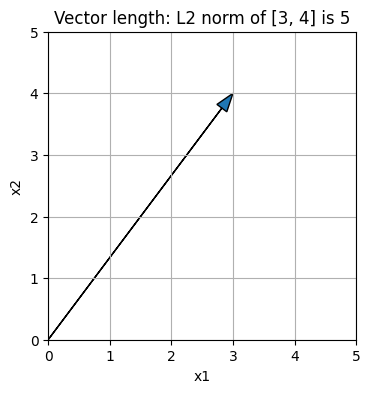

In [10]:
v = np.array([3.0, 4.0])
A = np.array([[1.0, 2.0], [3.0, 4.0]])

norm_table = pd.DataFrame({
    'Object': ['vector v', 'matrix A'],
    'L1 norm': [np.linalg.norm(v, ord=1), np.linalg.norm(A, ord=1)],
    'L2/Frobenius norm': [np.linalg.norm(v, ord=2), np.linalg.norm(A, ord='fro')]
})
display(norm_table.round(3))

plt.figure(figsize=(4, 4))
plt.arrow(0, 0, v[0], v[1], head_width=0.2, length_includes_head=True)
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.title('Vector length: L2 norm of [3, 4] is 5')
plt.xlabel('x1')
plt.ylabel('x2')
plt.gca().set_aspect('equal')
plt.show()


## Step 10: Distance and Cosine Similarity

Distance measures how far vectors are. Similarity measures how aligned they are.

### Euclidean distance

$$
\text{distance}(a,b) = \|a-b\|_2
$$

### Cosine similarity

$$
\cos(\theta) = \frac{a \cdot b}{\|a\|\|b\|}
$$

Where used:

- embeddings
- retrieval systems
- contrastive learning
- nearest-neighbor search
- recommendation systems

Cosine similarity focuses on direction, not magnitude.


### Distance vs Similarity

Distance and similarity are related, but they answer different questions.

| Question | Measurement |
|---|---|
| How far apart are these vectors? | distance |
| How much do these vectors point in the same direction? | similarity |

This is important for embeddings.

For text embeddings, two sentences can have different vector magnitudes but still point in a similar direction. In that case, cosine similarity can be more useful than raw Euclidean distance.


### Euclidean Distance

Formula:

$$
d(a,b) = \sqrt{(a_1-b_1)^2 + (a_2-b_2)^2 + \dots + (a_n-b_n)^2}
$$

**Where it is used:** clustering, nearest neighbors, anomaly detection, embedding search.

**Why it is useful:** it measures straight-line distance between two points.

**Deep learning example:** if an autoencoder reconstructs normal examples well but reconstructs abnormal examples poorly, the reconstruction error can be measured using a distance-like value.

**Common mistake:** using Euclidean distance on unscaled features. A large-scale feature can dominate the distance.


### Cosine Similarity

Formula:

$$
\cos(\theta) = \frac{a \cdot b}{\|a\|_2 \|b\|_2}
$$

Cosine similarity cares about angle, not raw length.

| Value | Meaning |
|---:|---|
| `1` | same direction |
| `0` | unrelated / perpendicular |
| `-1` | opposite direction |

**Where it is used:** text embeddings, image embeddings, semantic search, retrieval, recommendation.

**Why it is useful:** in embedding spaces, direction often carries meaning.

**Common mistake:** thinking cosine similarity is a probability. It is not a probability; it is an angle-based similarity score.


In [11]:
a = np.array([1.0, 2.0, 0.0])
b = np.array([2.0, 4.0, 0.0])
c = np.array([-2.0, 1.0, 0.0])

def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

rows = []
for name, vec in [('b', b), ('c', c)]:
    rows.append({
        'Compare a with': name,
        'Euclidean distance': np.linalg.norm(a - vec),
        'Cosine similarity': cosine(a, vec)
    })
display(pd.DataFrame(rows).round(3))


,Compare a with,Euclidean distance,Cosine similarity
0,b,2.236,1.0
1,c,3.162,0.0


### Output Meaning

Vector `b` points in the same direction as `a`, so cosine similarity is 1 even though its magnitude is larger.

This is why cosine similarity is common for embeddings: two texts can have different vector sizes but still point in a similar semantic direction.


## Step 11: Functions, Slope, and Derivatives

A function maps input to output.

Example:

$$
f(x) = x^2
$$

The **derivative** tells the slope of the function at a point.

For:

$$
f(x)=x^2
$$

The derivative is:

$$
f'(x)=2x
$$

Where used in deep learning:

- loss functions
- gradient descent
- backpropagation
- optimizer updates


### Why Derivatives Matter

A derivative tells how fast one value changes when another value changes.

In deep learning, we care about this question:

```text
If I slightly change this weight, how will the loss change?
```

If the derivative is positive, increasing the weight increases the loss. If the derivative is negative, increasing the weight decreases the loss. The optimizer uses this information to update weights.

Without derivatives, the model would not know how to improve its parameters.


### Derivative as Local Slope

A derivative is local. It describes the slope at one point, not the whole function.

For:

$$
f(x) = x^2
$$

Derivative:

$$
f'(x)=2x
$$

At different points:

| x | derivative 2x | meaning |
|---:|---:|---|
| -2 | -4 | function decreases as x increases |
| 0 | 0 | flat point |
| 2 | 4 | function increases as x increases |

**Common mistake:** thinking the derivative is the same everywhere. It changes depending on the point.


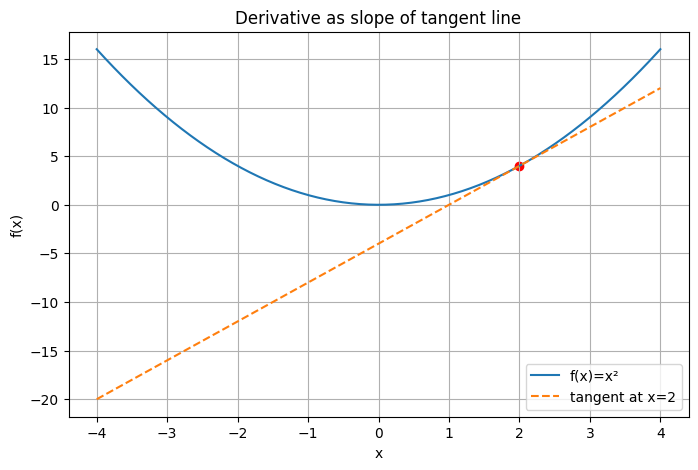

Derivative at x=2: 4.0


In [12]:
x = np.linspace(-4, 4, 200)
y = x ** 2
point = 2.0
slope = 2 * point
tangent = point**2 + slope * (x - point)

plt.plot(x, y, label='f(x)=x²')
plt.plot(x, tangent, '--', label='tangent at x=2')
plt.scatter([point], [point**2], color='red')
plt.title('Derivative as slope of tangent line')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.show()

print('Derivative at x=2:', slope)


## Step 12: Partial Derivatives

A partial derivative measures how a function changes with respect to one variable while holding other variables fixed.

Example:

$$
f(x,y)=x^2 + 3y
$$

Partial derivatives:

$$
\frac{\partial f}{\partial x}=2x
$$

$$
\frac{\partial f}{\partial y}=3
$$

Where used in deep learning:

A loss function depends on many weights. We need to know how the loss changes with respect to each weight.


### Why Partial Derivatives Are Needed

A neural network has many parameters. The loss depends on all of them.

Example:

```text
loss depends on w1, w2, w3, ..., wn
```

A partial derivative asks:

```text
If I change only this one parameter and keep the others fixed, what happens to the loss?
```

That is why partial derivatives are the foundation of learning each weight.

**Common mistake:** thinking one derivative is enough for the whole model. In a model with 1 million parameters, the optimizer needs gradient information for all 1 million parameters.


In [13]:
x_val = 2.0
y_val = 5.0
f = x_val**2 + 3*y_val
df_dx = 2*x_val
df_dy = 3

display(pd.DataFrame({
    'Quantity': ['f(x,y)', 'partial df/dx', 'partial df/dy'],
    'Value': [f, df_dx, df_dy]
}))


,Quantity,Value
0,"f(x,y)",19.0
1,partial df/dx,4.0
2,partial df/dy,3.0


## Step 13: Gradient Vector

The gradient is a vector of partial derivatives.

For:

$$
f(x,y)=x^2 + 3y
$$

The gradient is:

$$
\nabla f = [2x, 3]
$$

In deep learning, the gradient tells how the loss changes with respect to every trainable parameter.

Simple meaning:

```text
gradient = direction of steepest increase
negative gradient = direction to reduce loss
```


### Gradient as All Partial Derivatives Together

The gradient collects all partial derivatives into one vector.

If:

$$
L = L(w_1, w_2, w_3)
$$

Then:

$$
\nabla L = \left[\frac{\partial L}{\partial w_1}, \frac{\partial L}{\partial w_2}, \frac{\partial L}{\partial w_3}\right]
$$

The gradient tells the optimizer how each parameter affects the loss.

**Simple intuition:** gradient is the model's correction signal.

**Where used:** backpropagation, gradient descent, Adam, SGD, gradient clipping.

**Common mistake:** saying gradient is always the direction to move. Gradient points uphill for the loss. To reduce loss, we move in the negative gradient direction.


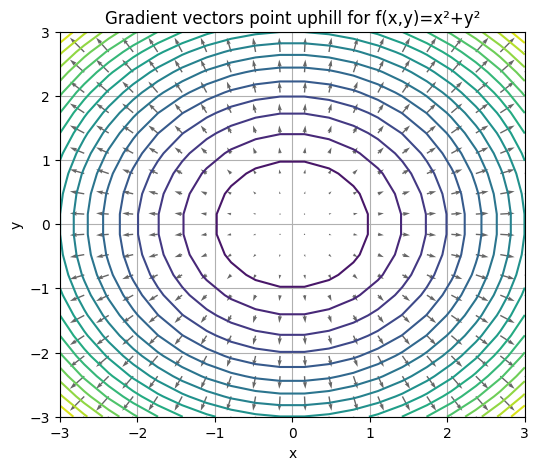

In [14]:
x_grid, y_grid = np.meshgrid(np.linspace(-3, 3, 20), np.linspace(-3, 3, 20))
z = x_grid**2 + y_grid**2
grad_x = 2 * x_grid
grad_y = 2 * y_grid

plt.figure(figsize=(6, 5))
plt.contour(x_grid, y_grid, z, levels=20)
plt.quiver(x_grid, y_grid, grad_x, grad_y, alpha=0.6)
plt.title('Gradient vectors point uphill for f(x,y)=x²+y²')
plt.xlabel('x')
plt.ylabel('y')
plt.show()


## Step 14: Gradient Descent Direction

Gradient points uphill. To reduce loss, we move in the opposite direction.

Update rule:

$$
w_{new} = w_{old} - \eta \nabla L(w)
$$

Where:

- $w$ = parameter
- $\eta$ = learning rate
- $\nabla L(w)$ = gradient of loss

This is the foundation of neural-network training.


,step,w,loss,gradient
0,0,-4.000,49.000,-14.000
1,1,-1.200,17.640,-8.400
2,2,0.480,6.350,-5.040
3,3,1.488,2.286,-3.024
4,4,2.093,0.823,-1.814
5,5,2.456,0.296,-1.089
6,6,2.673,0.107,-0.653
7,7,2.804,0.038,-0.392
8,8,2.882,0.014,-0.235
9,9,2.929,0.005,-0.141


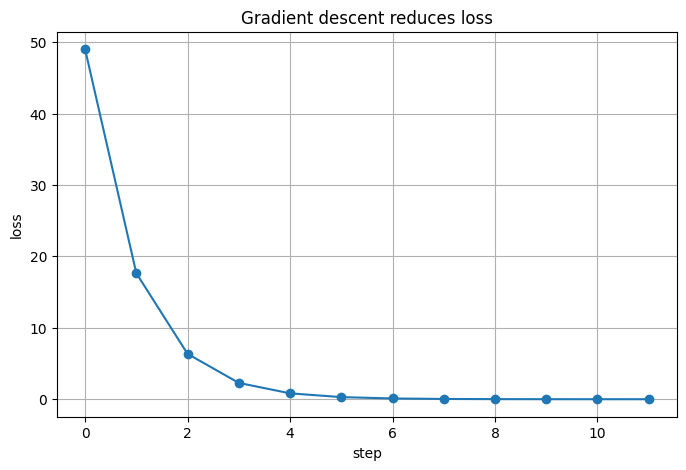

In [15]:
def loss(w):
    return (w - 3) ** 2

def grad(w):
    return 2 * (w - 3)

w = -4.0
lr = 0.2
rows = []
for step in range(12):
    rows.append({'step': step, 'w': w, 'loss': loss(w), 'gradient': grad(w)})
    w = w - lr * grad(w)

df_steps = pd.DataFrame(rows)
display(df_steps.round(3))

plt.plot(df_steps['step'], df_steps['loss'], marker='o')
plt.title('Gradient descent reduces loss')
plt.xlabel('step')
plt.ylabel('loss')
plt.show()


## Step 15: Chain Rule

Deep networks are nested functions.

Example:

$$
y = f(g(x))
$$

The chain rule says:

$$
\frac{dy}{dx} = \frac{dy}{dg} \cdot \frac{dg}{dx}
$$

Why it matters:

Backpropagation uses the chain rule to pass gradients backward through layers.

Deep learning connection:

```text
input → layer 1 → activation → layer 2 → loss
```

To update layer 1 weights, the model must know how layer 1 affected the final loss. That requires the chain rule.


### Why Chain Rule Is the Heart of Backpropagation

A deep network is a chain of functions.

```text
input → layer 1 → activation → layer 2 → activation → output → loss
```

The first layer affects the loss indirectly through every later layer. The chain rule tells us how to measure that indirect effect.

Without chain rule, we could update only the final layer easily, but not earlier layers.

Backpropagation is basically the chain rule applied efficiently from the loss backward through the network.

**Common mistake:** memorizing the chain rule formula without connecting it to layers. Think of it as “how much did this earlier value influence the final loss through all later steps?”


In [16]:
# y = (3x + 2)^2
x = 4.0
g = 3*x + 2
y = g**2
# dy/dx = dy/dg * dg/dx = 2g * 3
dy_dx = 2*g*3

print('x:', x)
print('g = 3x + 2:', g)
print('y = g²:', y)
print('dy/dx using chain rule:', dy_dx)


x: 4.0
g = 3x + 2: 14.0
y = g²: 196.0
dy/dx using chain rule: 84.0


## Step 16: Jacobian Intuition

A derivative of one output with respect to one input is a number.

But many deep learning operations have many inputs and many outputs.

The **Jacobian** stores all first-order partial derivatives for a vector-output function.

If:

```text
input vector has 2 values
output vector has 3 values
```

Then the Jacobian shape is:

```text
(3 outputs, 2 inputs)
```

Where used:

- understanding vector-valued functions
- backpropagation theory
- sensitivity analysis
- advanced optimization

Most frameworks do not explicitly build the full Jacobian for every layer because it would be huge. They use efficient vector-Jacobian products.


In [17]:
# Function: f([x,y]) = [x+y, x*y, x^2]
x, y = 2.0, 3.0
J = np.array([
    [1, 1],      # d(x+y)/dx, d(x+y)/dy
    [y, x],      # d(x*y)/dx, d(x*y)/dy
    [2*x, 0],    # d(x^2)/dx, d(x^2)/dy
])
display(pd.DataFrame(J, columns=['d/dx', 'd/dy'], index=['x+y', 'x*y', 'x^2']))
print('Jacobian shape:', J.shape)


,d/dx,d/dy
x+y,1.0,1.0
x*y,3.0,2.0
x^2,4.0,0.0


Jacobian shape: (3, 2)


## Step 17: Hessian and Curvature Intuition

The **Hessian** contains second-order derivatives.

First derivative tells slope.

Second derivative tells curvature.

Where used:

- understanding optimization difficulty
- Newton-style methods
- saddle points
- curvature analysis

Deep learning usually uses first-order methods like SGD/Adam because the Hessian is too expensive for large networks. But curvature intuition helps explain why optimization can be hard.


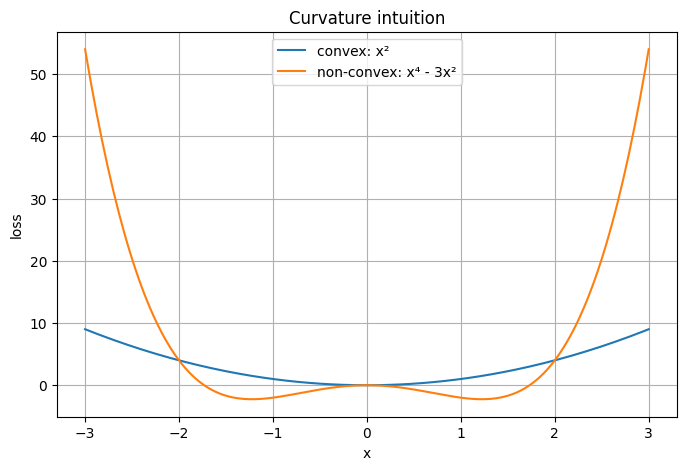

In [18]:
x = np.linspace(-3, 3, 200)
convex = x**2
nonconvex = x**4 - 3*x**2

plt.plot(x, convex, label='convex: x²')
plt.plot(x, nonconvex, label='non-convex: x⁴ - 3x²')
plt.title('Curvature intuition')
plt.xlabel('x')
plt.ylabel('loss')
plt.legend()
plt.show()


## Step 18: Probability Basics

For classification, neural networks often output probabilities.

Probability rules:

- probabilities are between 0 and 1
- probabilities over all classes sum to 1 for multiclass classification

Example:

```text
P(cat) = 0.70
P(dog) = 0.20
P(rabbit) = 0.10
```

The model predicts the class with the highest probability, but the loss uses the probability assigned to the true class.


In [19]:
probs = np.array([0.7, 0.2, 0.1])
classes = ['cat', 'dog', 'rabbit']
display(pd.DataFrame({'class': classes, 'probability': probs}))
print('Sum of probabilities:', probs.sum())
print('Predicted class:', classes[np.argmax(probs)])


,class,probability
0,cat,0.7
1,dog,0.2
2,rabbit,0.1


Sum of probabilities: 0.9999999999999999
Predicted class: cat


## Step 19: Likelihood and Log-Likelihood

**Likelihood** measures how much probability the model assigns to the observed correct labels.

If the true class is `cat`, and the model assigns:

```text
P(cat)=0.70
```

then the likelihood for that example is `0.70`.

For many examples, likelihood multiplies probabilities. Multiplying many small numbers can underflow, so we usually use log-likelihood.

Log-likelihood turns multiplication into addition:

$$
\log(a \times b) = \log(a) + \log(b)
$$

Loss functions often minimize **negative log-likelihood**.


In [20]:
true_class_probs = np.array([0.8, 0.6, 0.9, 0.7])
likelihood = np.prod(true_class_probs)
log_likelihood = np.sum(np.log(true_class_probs))
negative_log_likelihood = -log_likelihood

display(pd.DataFrame({
    'Quantity': ['likelihood product', 'log-likelihood sum', 'negative log-likelihood'],
    'Value': [likelihood, log_likelihood, negative_log_likelihood]
}).round(4))


,Quantity,Value
0,likelihood product,0.3024
1,log-likelihood sum,-1.1960
2,negative log-likelihood,1.1960


## Step 20: Entropy

Entropy measures uncertainty in a probability distribution.

Formula:

$$
H(p) = -\sum_i p_i \log(p_i)
$$

Low entropy:

```text
[0.99, 0.01]
```

High entropy:

```text
[0.50, 0.50]
```

Where used:

- uncertainty measurement
- decision trees / information gain
- classification loss intuition
- reinforcement learning exploration
- generative modeling


### Entropy as Uncertainty

Entropy measures uncertainty in a distribution.

If a model says:

```text
[1.0, 0.0, 0.0]
```

there is no uncertainty. The model is fully concentrated on one class.

If a model says:

```text
[0.33, 0.33, 0.34]
```

there is high uncertainty. The probability is spread across classes.

**Where used in DL:** classification uncertainty, active learning, reinforcement learning exploration, information theory, decision trees, generative modeling.

**Common mistake:** thinking entropy means error. Entropy is uncertainty, not correctness. A model can be confidently wrong with low entropy.


,distribution,probabilities,entropy_bits
0,very confident,"[0.99, 0.01]",0.081
1,moderately confident,"[0.75, 0.25]",0.811
2,uncertain,"[0.5, 0.5]",1.000


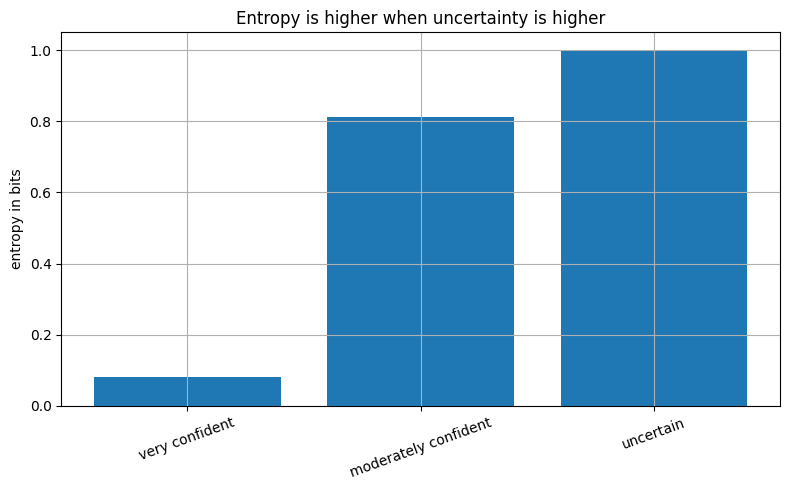

In [21]:
def entropy(p):
    p = np.array(p)
    return -np.sum(p * np.log2(p + 1e-12))

dists = {
    'very confident': [0.99, 0.01],
    'moderately confident': [0.75, 0.25],
    'uncertain': [0.5, 0.5]
}
rows = [{'distribution': k, 'probabilities': v, 'entropy_bits': entropy(v)} for k, v in dists.items()]
display(pd.DataFrame(rows).round(3))

plt.bar(dists.keys(), [entropy(v) for v in dists.values()])
plt.ylabel('entropy in bits')
plt.title('Entropy is higher when uncertainty is higher')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Step 21: Cross-Entropy

Cross-entropy measures how well a predicted distribution matches the true distribution.

Formula:

$$
H(p,q) = -\sum_i p_i \log(q_i)
$$

Where:

- $p$ = true distribution
- $q$ = predicted distribution

For one-hot labels, cross-entropy becomes:

```text
-negative log probability of the true class
```

This is why wrong confident predictions are punished strongly.


### Cross-Entropy as Classification Loss

Cross-entropy compares the true label distribution with the predicted distribution.

For one-hot labels, it focuses on the probability assigned to the correct class.

Example:

```text
true class = cat
model gives P(cat) = 0.90 → small loss
model gives P(cat) = 0.05 → large loss
```

This is why cross-entropy is used for classification. It does not only ask “was the final class correct?” It asks “how much probability did you assign to the correct class?”

**Common mistake:** applying softmax twice before cross-entropy. Many frameworks have a loss function that expects raw logits and applies stable softmax internally.


In [22]:
y_true = np.array([1, 0, 0])
good_pred = np.array([0.9, 0.08, 0.02])
okay_pred = np.array([0.6, 0.3, 0.1])
bad_pred = np.array([0.05, 0.15, 0.8])

def cross_entropy(p, q):
    return -np.sum(p * np.log(q + 1e-12))

rows = []
for name, q in [('good', good_pred), ('okay', okay_pred), ('bad', bad_pred)]:
    rows.append({'prediction': name, 'true_class_probability': q[0], 'cross_entropy_loss': cross_entropy(y_true, q)})
display(pd.DataFrame(rows).round(3))


,prediction,true_class_probability,cross_entropy_loss
0,good,0.90,0.105
1,okay,0.60,0.511
2,bad,0.05,2.996


### Output Meaning

The good prediction gives high probability to the true class, so the loss is small.

The bad prediction gives low probability to the true class, so the loss is large.

Common mistake: thinking cross-entropy checks only whether the final predicted class is correct. It also cares how much probability the model assigned to the correct class.


## Step 22: KL Divergence

KL divergence measures how different one probability distribution is from another.

Formula:

$$
D_{KL}(P || Q) = \sum_i P_i \log\left(\frac{P_i}{Q_i}\right)
$$

Where used in deep learning:

- VAEs: keep latent distribution close to a normal distribution
- knowledge distillation: student distribution compared with teacher distribution
- reinforcement learning policy updates
- distribution shift analysis

Important: KL divergence is not symmetric.

```text
KL(P || Q) is not always equal to KL(Q || P)
```


### KL Divergence as Distribution Difference

KL divergence compares two probability distributions.

It answers:

```text
If P is the true/reference distribution, how inefficient is it to use Q instead?
```

This is deeper than ordinary distance because distributions have probability meaning.

**Where it appears in deep learning:**

- **VAE:** keeps learned latent distribution close to a simple prior distribution.
- **Knowledge distillation:** student model learns to match teacher model probabilities.
- **RL:** limits how much a new policy changes from an old policy.
- **Monitoring:** compares current prediction distribution against past distribution.

**Common mistake:** treating KL divergence like normal distance. KL is not symmetric and does not behave like Euclidean distance.


In [23]:
def kl(p, q):
    p = np.array(p)
    q = np.array(q)
    return np.sum(p * np.log((p + 1e-12) / (q + 1e-12)))

P = np.array([0.7, 0.2, 0.1])
Q = np.array([0.6, 0.3, 0.1])
R = np.array([0.1, 0.2, 0.7])

display(pd.DataFrame({
    'Comparison': ['KL(P || Q)', 'KL(Q || P)', 'KL(P || R)'],
    'Value': [kl(P, Q), kl(Q, P), kl(P, R)]
}).round(4))


,Comparison,Value
0,KL(P || Q),0.0268
1,KL(Q || P),0.0291
2,KL(P || R),1.1675


### Output Meaning

`P` and `Q` are similar, so KL is small.

`P` and `R` are very different, so KL is larger.

This idea appears later in VAEs and model distillation.


## Step 23: Numerical Stability

Deep learning uses exponential, logarithm, division, and repeated multiplication. These operations can cause numerical problems.

Common problems:

| Problem | Meaning | Example |
|---|---|---|
| Overflow | number becomes too large | `exp(1000)` |
| Underflow | number becomes too close to zero | multiplying many tiny probabilities |
| log(0) | undefined | `log(0)` gives `-inf` |
| division by zero | undefined | normalization with zero denominator |

Stable implementations avoid these problems.


### Why Numerical Stability Is a Real Deep Learning Problem

Computers cannot represent all real numbers perfectly. Deep learning repeatedly applies exponentials, logarithms, divisions, and matrix operations. Small numerical issues can become big training failures.

Examples:

```text
exp(1000) → too large → overflow
log(0)   → undefined → -inf
0 / 0    → undefined → nan
```

Once `nan` appears in loss or gradients, training often becomes unusable.

**Common places this happens:** softmax, cross-entropy, normalization, very high learning rate, exploding gradients, mixed precision training.

**Common mistake:** assuming a formula that is mathematically correct is automatically safe in code. Stable implementations often rewrite the same formula to avoid overflow/underflow.


In [24]:
values = np.array([10, 100, 1000], dtype=np.float64)
rows = []
for v in values:
    try:
        ev = np.exp(v)
    except Exception as e:
        ev = str(e)
    rows.append({'x': v, 'exp(x)': ev})
display(pd.DataFrame(rows))

print('log(0) without epsilon:', np.log(0))
print('log(0 + 1e-12) with epsilon:', np.log(1e-12))


C:\Users\91832\AppData\Local\Temp\ipykernel_14848\1738317693.py:5: RuntimeWarning: overflow encountered in exp
  ev = np.exp(v)


,x,exp(x)
0,10.0,2.202647e+04
1,100.0,2.688117e+43
2,1000.0,inf


log(0) without epsilon: -inf
log(0 + 1e-12) with epsilon: -27.631021115928547


C:\Users\91832\AppData\Local\Temp\ipykernel_14848\1738317693.py:11: RuntimeWarning: divide by zero encountered in log
  print('log(0) without epsilon:', np.log(0))


## Step 24: Stable Softmax and Log-Sum-Exp

Softmax formula:

$$
\text{softmax}(z_i)=\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

Problem: if logits are large, `exp(logit)` can overflow.

Stable trick: subtract the maximum logit before exponentiating.

$$
\text{softmax}(z_i)=\frac{e^{z_i - \max(z)}}{\sum_j e^{z_j - \max(z)}}
$$

This does not change the final probabilities, but it prevents overflow.


### Why Stable Softmax Works

Softmax uses exponentials:

$$
\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

If logits are huge, exponentials overflow. But softmax is unchanged if we subtract the same constant from every logit.

So we subtract the maximum logit:

```text
[1000, 999, 998] → [0, -1, -2]
```

The probabilities stay the same, but exponentials become safe.

**Common mistake:** implementing softmax manually without subtracting the maximum. In real DL code, use framework-provided stable softmax/cross-entropy functions.


In [25]:
def softmax_unstable(z):
    ez = np.exp(z)
    return ez / ez.sum()

def softmax_stable(z):
    shifted = z - np.max(z)
    ez = np.exp(shifted)
    return ez / ez.sum()

small_logits = np.array([2.0, 1.0, 0.1])
large_logits = np.array([1000.0, 999.0, 998.0])

print('Stable softmax small logits:', softmax_stable(small_logits))
print('Stable softmax large logits:', softmax_stable(large_logits))
try:
    print('Unstable softmax large logits:', softmax_unstable(large_logits))
except Exception as e:
    print('Unstable softmax failed:', e)


Stable softmax small logits: [0.65900114 0.24243297 0.09856589]
Stable softmax large logits: [0.66524096 0.24472847 0.09003057]
Unstable softmax large logits: [nan nan nan]


C:\Users\91832\AppData\Local\Temp\ipykernel_14848\2521976929.py:2: RuntimeWarning: overflow encountered in exp
  ez = np.exp(z)
C:\Users\91832\AppData\Local\Temp\ipykernel_14848\2521976929.py:3: RuntimeWarning: invalid value encountered in divide
  return ez / ez.sum()


### Log-Sum-Exp Idea

Log-sum-exp is a stable way to compute:

$$
\log\left(\sum_i e^{x_i}\right)
$$

Stable form:

$$
\log\left(\sum_i e^{x_i}\right) = m + \log\left(\sum_i e^{x_i-m}\right)
$$

where:

$$
m = \max(x)
$$

This idea appears inside stable softmax and cross-entropy implementations.


In [26]:
def logsumexp_stable(x):
    m = np.max(x)
    return m + np.log(np.sum(np.exp(x - m)))

x = np.array([1000.0, 999.0, 998.0])
print('stable logsumexp:', logsumexp_stable(x))


stable logsumexp: 1000.4076059644444


## Step 25: Common Math Mistakes in Deep Learning

| Mistake | Why it causes problems |
|---|---|
| Ignoring tensor shapes | matrix multiplication fails or silently gives wrong interpretation |
| Confusing rows and columns | features and samples get swapped |
| Forgetting batch dimension | model receives wrong input shape |
| Using elementwise multiply instead of dot product | neuron calculation becomes wrong |
| Trusting broadcasting blindly | wrong axis can be broadcast silently |
| Using unstable softmax | overflow creates `nan` or invalid probabilities |
| Taking `log(0)` | creates `-inf` loss |
| Mixing logits and probabilities | loss function may be used incorrectly |
| Confusing entropy and cross-entropy | uncertainty vs prediction loss are different ideas |
| Assuming KL divergence is symmetric | `KL(P||Q)` and `KL(Q||P)` can differ |


## Step 26: Final Checklist

Before moving to Module 3, you should be able to answer:

- What is the difference between scalar, vector, matrix, and tensor?
- What do shape, axis, rank, and dtype mean?
- Why is the batch dimension important?
- How does a dot product relate to one neuron?
- How does matrix multiplication relate to one layer?
- Why is broadcasting used for bias addition?
- What is the difference between L1 and L2 norm?
- Why is cosine similarity useful for embeddings?
- What does a derivative measure?
- What is a partial derivative?
- What is a gradient vector?
- Why does gradient descent move in the negative gradient direction?
- Why is the chain rule necessary for backpropagation?
- What are Jacobian and Hessian used to understand?
- What is likelihood?
- Why do we use log-likelihood?
- What does entropy measure?
- What does cross-entropy measure?
- What does KL divergence compare?
- Why can softmax overflow?
- How does stable softmax fix overflow?

Next module: **Neurons, Perceptrons, and Multilayer Perceptrons**.
